In [75]:
import pandas as pd

from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset("lukebarousse/data_jobs")
df = dataset["train"].to_pandas()

job_posted_date = pd.to_datetime(df["job_posted_date"])


# df.fillna() -- filling the median salary for the missing values in the dataset
# df.dropna()
# df.drop_duplicates() -- Dropping duplicates from the dataset


In [76]:
# monthly job demand for data science jobs

df_US = df[df["job_country"] == "United States"]


In [77]:
df_US['job_posted_date'] = pd.to_datetime(df_US['job_posted_date'])

df_US['job_posted_month'] = df_US['job_posted_date'].dt.strftime('%B')
df_US['job_posted_month']

0             June
3             July
5         November
6            March
9            April
            ...   
785673     October
785685        July
785692       April
785703     January
785705     January
Name: job_posted_month, Length: 206292, dtype: str

In [78]:
job_posted_month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

job_posted_month_order

['January',
 'February',
 'March',
 'April',
 'May',
 'June',
 'July',
 'August',
 'September',
 'October',
 'November',
 'December']

In [79]:
df_US["job_posted_month"] = pd.Categorical(df_US["job_posted_month"], categories=job_posted_month_order, ordered=True)

df_US["job_posted_month"]

0             June
3             July
5         November
6            March
9            April
            ...   
785673     October
785685        July
785692       April
785703     January
785705     January
Name: job_posted_month, Length: 206292, dtype: category
Categories (12, str): ['January' < 'February' < 'March' < 'April' ... 'September' < 'October' < 'November' < 'December']

In [80]:
df_US["job_posted_month"].unique()

['June', 'July', 'November', 'March', 'April', ..., 'January', 'August', 'December', 'October', 'May']
Length: 12
Categories (12, str): ['January' < 'February' < 'March' < 'April' ... 'September' < 'October' < 'November' < 'December']

In [81]:
df_US_pivot_table =df_US.pivot_table(
    index= "job_posted_month",
    columns='job_title_short',
    aggfunc='size'
).sort_index()

df_US_pivot_table 

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
January,527,36,8494,2655,6915,60,1544,773,1552,114
February,447,24,6124,3060,4956,56,1258,878,1127,90
March,438,19,6218,3183,4779,59,1114,829,1150,115
April,565,40,6049,2801,4867,51,1025,781,991,112
May,279,20,4993,2976,4377,49,839,746,914,90
June,446,32,5683,2893,4645,48,1009,812,1033,93
July,581,39,5201,2570,4876,65,883,747,1095,153
August,903,39,6634,3269,6318,68,1186,903,1515,194
September,897,50,4639,3224,4568,113,805,775,1014,228


In [82]:
top_3 = df_US['job_title_short'].value_counts().head(3)

top_3 = top_3.index.tolist()

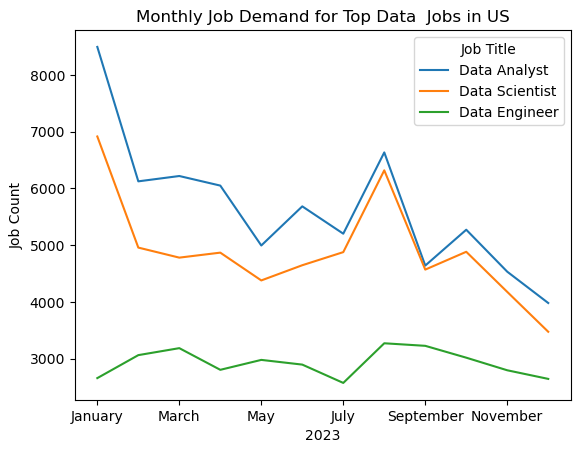

In [85]:
df_US_pivot_table[top_3].plot(kind='line')
plt.title('Monthly Job Demand for Top Data  Jobs in US')
plt.xlabel('2023')
plt.ylabel('Job Count')
plt.legend(title='Job Title')
plt.show()